<a href="https://colab.research.google.com/github/gulgom1227-coder/2026_2S_phonology/blob/main/06_Speech_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Audio Processing

## 1. Waveform

In [1]:
# Import packages
import librosa
import numpy as np
import matplotlib.pyplot as plt #그래프 디자인 보조. 하위패키지만 불러옴

#음성은 숫자 데이터

In [3]:
# Load audio
audio, sr = librosa.load("aeiou.wav")

print(audio.shape) # 개수가 48600개니 즉 약 2초쯤 될거임
print(sr) # sampling의 개수 출력 (librosa 기본 22050Hz)
len(audio) #1차원 데이터니 len사용 가능
print(len(audio)/sr) #초 계산

(48600,)
22050
2.204081632653061


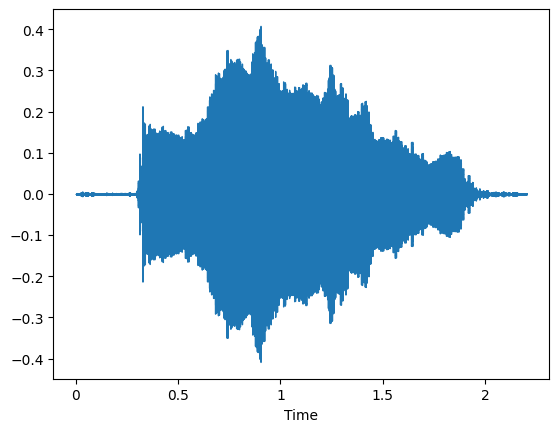

In [4]:
# Visualize audio
librosa.display.waveshow(audio, sr=sr) #샘플링 레이트 지정가능 기본 22050

#keyword argument: sr=sr. 변수에 이름을 붙여서 실행시킴. 뭐 다른 변수끼리 순서 바꾸고 그런 편의성으로 쓴대

#가로축은 시간, 세로축은 공기압력과 관련(진폭, amplitude). 클수록 큰 소리
#특정 사인파가 반복되는 패턴을 보임. >> 주기(cycle). 초당 주기의 수 = 주파수. 단위 Hz
#스펙트럼: 복잡합 파형은 여러 주파수와 진폭을 지닌 사인파의 조합을 통해 나타남. 진폭이 클수록 많이 관여
#푸리에 변환을 통해 소리로부터 스펙트럼 출력 가능
#기초 주파수 막대 그래프로 나타남 가로 주파수, 세로 진폭. 나타나는 주파수는 서로 하모닉(배수 관계)
#스펙트로그램: 흑백 사진 그거. 스펙트럼을 시간대 별로 쌓은 그림. short time 푸리에변환 (STFT)
#3차원 스펙트로그램을 2차원으로 나타내면 흑백으로 진폭을 나타냄. 가로 시간, 세로 주파수. >> 모음 분석에 용이


## 2. Spectrogram

In [5]:
# Pre-emphasis 아마 고주파 대비 키울려고 하는 건듯
pre_audio = librosa.effects.preemphasis(audio)

In [6]:
print(pre_audio) #숫자 값들을 살짝 조정. 개수는 변화 X

[ 3.5340199e-06 -1.8459640e-06  2.2987556e-06 ... -6.0146851e-07
  4.8848290e-07 -4.1576220e-07]


In [7]:
# Short-time Fourier Transform (STFT)
n_fft = 2048
win_length = int(sr * 0.005) #미분 구간. 윈도우 >> 윈도우 길이는 0.005초
hop_length = int(sr * 0.001) #다음 윈도우의 이동 길이
#int: 소수점 버림 >> 샘플 개수가 소수가 될 수 없음

stft_result = librosa.stft(
    pre_audio,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length
)

print(stft_result.shape) #(1025,2210) >> 1025는 주파수 값 개수, 2210은 시간 = 윈도의 개수
#왼쪽꺼는 내부 함수 변수임. 그 로컬 변수. 오른쪽 꺼는 글로벌 변수임. 걍 이렇게 헷갈리게 쓰는게 관습이란다 시팔.

print(stft_result) #스펙트로그램은 복소수의 형태의 값을 지님. 각각의 정보를 표시하기 위함. 뭔 정보인지는 몰루

stft_result[0,0] #첫 윈도우의 1번 주파수 정보

(1025, 2210)
[[ 4.8575902e-04+0.00000000e+00j  1.1697997e-03+0.00000000e+00j
   1.9809785e-03+0.00000000e+00j ... -7.4451003e-07+0.00000000e+00j
  -4.5105742e-05+0.00000000e+00j -7.5497890e-05+0.00000000e+00j]
 [-4.8416987e-04+3.64714797e-05j -1.1679592e-03+4.22354024e-05j
  -1.9767878e-03+4.54904875e-05j ...  5.5683216e-07-1.82092344e-06j
   4.5147481e-05-5.27340262e-06j  7.5512471e-05+2.10867938e-06j]
 [ 4.7941782e-04-7.26406288e-05j  1.1624563e-03-8.41363653e-05j
   1.9642541e-03-9.04502012e-05j ...  6.0697123e-09+3.59838941e-06j
  -4.5273217e-05+1.05404442e-05j -7.5554650e-05-4.23581287e-06j]
 ...
 [-1.9579945e-06-1.36809558e-06j  4.0582527e-06-7.13354723e-07j
   5.9066419e-06+2.45265028e-06j ...  2.4801839e-06+4.55291143e-07j
   2.4308190e-06-1.23136999e-06j -3.5225394e-06-1.99827966e-07j]
 [ 1.8533739e-06+6.74453702e-07j -3.7535372e-06+3.86309722e-07j
  -6.2895401e-06-1.26116686e-06j ... -2.4538540e-06-2.21817473e-07j
  -2.3978714e-06+6.11621203e-07j  3.4383870e-06+1.03106814e-07

np.complex64(0.00048575902+0j)

In [8]:
# Amplitude -> dB
magnitude = np.abs(stft_result) #위의 뭔지 모를 정보들에서 절댓값 처리로 진폭 정보를 취함.
print(magnitude) # 허수부가 정수부로 바뀌면서 진폭의 크기가 됨
spec_db = librosa.amplitude_to_db(magnitude, ref=np.max(magnitude)) #진폭단위 데시벨로 변환 >> log를 취하므로 대비를 주는 목적
#ref: 기준점 설정 >> np.max(magnitude)가 0데시벨

print(np.max(spec_db))
print(np.min(spec_db))

[[4.8575902e-04 1.1697997e-03 1.9809785e-03 ... 7.4451003e-07
  4.5105742e-05 7.5497890e-05]
 [4.8554159e-04 1.1687226e-03 1.9773112e-03 ... 1.9041597e-06
  4.5454417e-05 7.5541910e-05]
 [4.8488981e-04 1.1654971e-03 1.9663356e-03 ... 3.5983946e-06
  4.6484030e-05 7.5673299e-05]
 ...
 [2.3886037e-06 4.1204721e-06 6.3956172e-06 ... 2.5216270e-06
  2.7249134e-06 3.5282028e-06]
 [1.9722784e-06 3.7733639e-06 6.4147375e-06 ... 2.4638591e-06
  2.4746448e-06 3.4399327e-06]
 [1.8179999e-06 3.6506772e-06 6.4183500e-06 ... 2.4451083e-06
  2.3867096e-06 3.4102602e-06]]
0.0
-80.0


Text(0, 0.5, 'Frequency (Hz)')

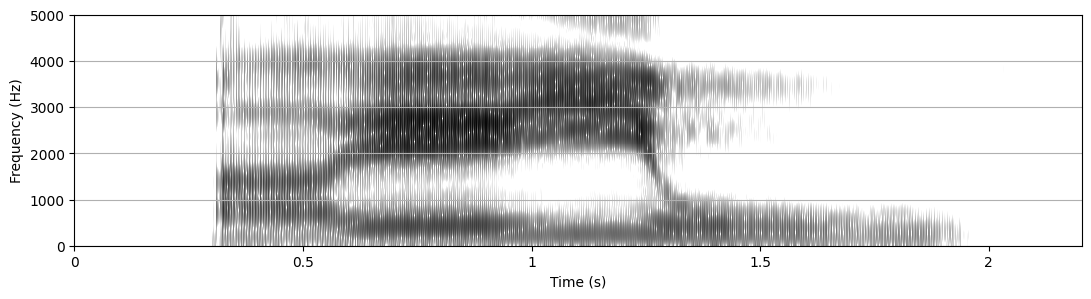

In [9]:
# Visualize spectrogram
plt.figure(figsize=(13, 3)) #전체 바탕 설정. 그래프 사이즈 결정

librosa.display.specshow(
    spec_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    cmap="gray_r", #색깔
    vmin=-40,# 이게 흰놈 설정, 이 아래 값들은 싹다 흰색
    vmax=0 # 이게 검은놈 설정
)
#librosa내에도 따로 그래프 표현 함수 존재

plt.ylim(0, 5000)
plt.xlim(0, len(audio) / sr)
plt.grid(axis="y")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
#plt.show() colab에서는 입력안해도 출력됨.

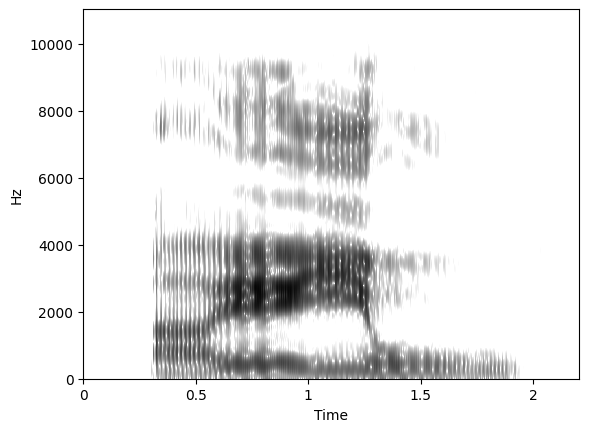

In [10]:
librosa.display.specshow(
    spec_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    cmap="gray_r",
    vmin=-40,
    vmax=0
)